# Experiment: Anonymizers AggFace

This notebook analyzes the results from running the `anonymizers_aggface` experiment.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from meles.paths import repository_root

sns.set_theme(style="whitegrid")

ROOT = repository_root()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results" / "anonymizers_aggface.parquet"

ANONYMIZERS = ["none", "gaussianblur", "pixelation", "blackbar"]
# Which leg AggFace (8 frames per reconstruction) ran on; the other leg used no frame aggregation.
AGGREGATED_ON = ["neither", "gallery", "samples", "both"]

results = pd.read_parquet(RESULTS)
identities = results["identity"].nunique()
chance = 1 / identities
print(f"{RESULTS.relative_to(ROOT)}: {len(results):,} rows, {identities} identities, chance top-1 = {chance:.4f}")

results/anonymizers_aggface.parquet: 1,843,072 rows, 600 identities, chance top-1 = 0.0017


In [2]:
# Both legs anonymized the same way, scored with similarities averaged over each query video.
same = (results["samples_frame_anonymizer"] == results["gallery_frame_anonymizer"])# & (results["score_aggregator"] == "max_mean")
legs = results.loc[same].rename(columns={"samples_frame_anonymizer": "anonymizer"})

# Aggregator keys are '{scope}_{method}'; only the method says whether AggFace ran on that leg.
gallery_agg = legs["gallery_frame_aggregator"].str.split("_", n=1).str[1] != "none"
samples_agg = legs["samples_frame_aggregator"].str.split("_", n=1).str[1] != "none"
legs["aggregated on"] = np.select(
    [gallery_agg & samples_agg, gallery_agg, samples_agg], ["both", "gallery", "samples"], default="neither"
)
legs["anonymizer"] = pd.Categorical(legs["anonymizer"], ANONYMIZERS)
legs["aggregated on"] = pd.Categorical(legs["aggregated on"], AGGREGATED_ON)

# Every cell should hold the same query videos, otherwise the conditions are scored on different people.
legs.groupby(["anonymizer", "aggregated on"], observed=True).size().unstack()

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,28798,28798,28798,28798
gaussianblur,28798,28798,28798,28798
pixelation,28798,28798,28798,28798
blackbar,28798,28798,28798,28798


## Where to aggregate: gallery, samples, both or neither

Top-1 when AggFace reconstructs faces on the gallery (per identity and fold), on the samples (per video), on both, or on neither. Gallery and samples carry the same anonymization, and the score averages similarities over each query video (`max_mean`). Each identity counts once: its videos are averaged first, and the whiskers are a 95% bootstrap interval over identities.

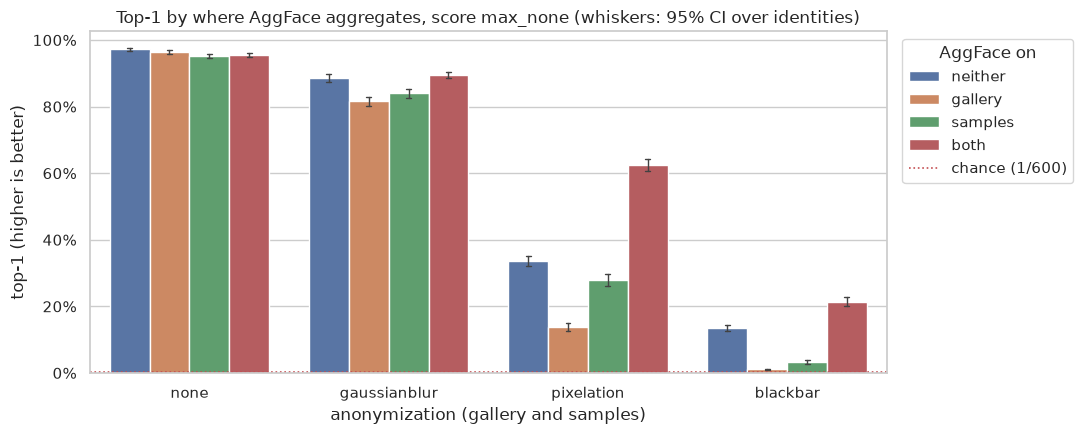

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,97.199997,96.400002,95.300003,95.599998
gaussianblur,88.599998,81.599998,84.000000,89.599998
pixelation,33.700001,13.900000,27.900000,62.400002
blackbar,13.400000,1.100000,3.300000,21.400000


In [3]:
legs_max_none = legs[legs["score_aggregator"] == "max_none"]
per_identity = (
    legs_max_none.groupby(["anonymizer", "aggregated on", "identity"], observed=True)["top-1"].mean().reset_index()
)

fig, axis = plt.subplots(figsize=(11, 4.5))
sns.barplot(
    per_identity,
    x="anonymizer",
    y="top-1",
    hue="aggregated on",
    order=ANONYMIZERS,
    hue_order=AGGREGATED_ON,
    errorbar=("ci", 95),
    n_boot=1000,
    seed=0,
    capsize=0.1,
    err_kws={"linewidth": 1},
    ax=axis,
)
axis.axhline(chance, color="#C44E52", linestyle=":", linewidth=1.2, label=f"chance (1/{identities})")
axis.set_xlabel("anonymization (gallery and samples)")
axis.set_ylabel("top-1 (higher is better)")
axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.grid(axis="x", visible=False)
axis.legend(title="AggFace on", loc="upper left", bbox_to_anchor=(1.01, 1))
axis.set_title("Top-1 by where AggFace aggregates, score max_none (whiskers: 95% CI over identities)")
fig.tight_layout()
fig.savefig(IMAGES / "09_aggregated_on.png", dpi=150)
plt.show()

per_identity.pivot_table(index="anonymizer", columns="aggregated on", values="top-1", observed=True).mul(100).round(1)

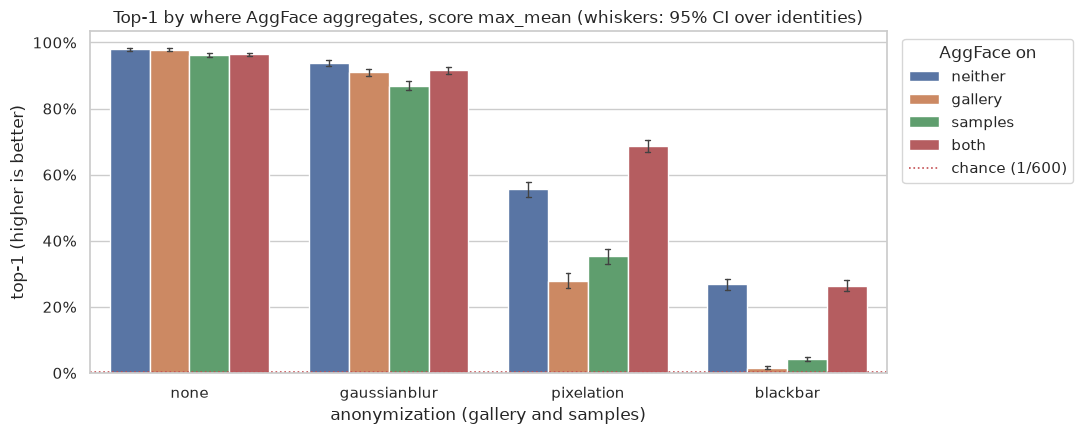

aggregated on,neither,gallery,samples,both
anonymizer,,,,
none,98.000000,97.800003,96.300003,96.400002
gaussianblur,93.900002,91.000000,86.900002,91.500000
pixelation,55.500000,27.900000,35.299999,68.800003
blackbar,26.900000,1.500000,4.200000,26.400000


In [4]:
legs_max_mean = legs[legs["score_aggregator"] == "max_mean"]
per_identity = (
    legs_max_mean.groupby(["anonymizer", "aggregated on", "identity"], observed=True)["top-1"].mean().reset_index()
)

fig, axis = plt.subplots(figsize=(11, 4.5))
sns.barplot(
    per_identity,
    x="anonymizer",
    y="top-1",
    hue="aggregated on",
    order=ANONYMIZERS,
    hue_order=AGGREGATED_ON,
    errorbar=("ci", 95),
    n_boot=1000,
    seed=0,
    capsize=0.1,
    err_kws={"linewidth": 1},
    ax=axis,
)
axis.axhline(chance, color="#C44E52", linestyle=":", linewidth=1.2, label=f"chance (1/{identities})")
axis.set_xlabel("anonymization (gallery and samples)")
axis.set_ylabel("top-1 (higher is better)")
axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
axis.grid(axis="x", visible=False)
axis.legend(title="AggFace on", loc="upper left", bbox_to_anchor=(1.01, 1))
axis.set_title("Top-1 by where AggFace aggregates, score max_mean (whiskers: 95% CI over identities)")
fig.tight_layout()
fig.savefig(IMAGES / "09_aggregated_on.png", dpi=150)
plt.show()

per_identity.pivot_table(index="anonymizer", columns="aggregated on", values="top-1", observed=True).mul(100).round(1)